# About this Notebook

This is a Python notebook. This is the notebook you'll use to run and create the analysis code on pickle data sets. Pickle files are created and premanufactured from ROOT files from MicroBooNE LAr experiment.

You should have access to: example_neutrino.ipynb, neutrino_function.py, data folder. You are free to modify neutrino_function.py or create your own plotting functions.

**IMPORTANT:** It is strongly recommended that only **one** student of a lab pair should edit this notebook and the files contained within the server directories. This is because both students cannot see the same live edit of the notebook or files at the same time, and it is easy to accidently overwrite each other.

Code that is commented out with two hashtags should be uncommented when in use.

# All imports

The basic libraries, you may import more if there are present on the server's environment. If you dont have these packages installed on your local machine, you can use **pip install X** or **pip3 install X** to start using them.

In [1]:
import numpy as np
import uproot3
import pickle

import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import Neutrino_functions

from math import *
import scipy as sci

# MACHINE LEARNING IMPORTS
import sklearn
from sklearn import tree
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

# Opening the MC and data frames

In [2]:
# MC
MC_file = './data/MC_EXT_flattened.pkl'

# Data
data_file = './data/data_flattened.pkl'


# Open file as pandas dataframe
MC_EXT = pd.read_pickle(MC_file)
data = pd.read_pickle(data_file)

# removing 'Subevent' from data
MC_EXT = MC_EXT.drop('Subevent', axis = 1)
data = data.drop('Subevent', axis = 1)

# You can display the dataframe by uncommenting these lines and running the cell

In [3]:
# Uncomment these lines to display the dataframes
pd.set_option('display.max_columns', 100)
# displays top 10 results.
data.head(10)

,_closestNuCosmicDist,trk_len_v,trk_distance_v,category,topological_score,trk_sce_end_z_v,trk_sce_end_y_v,trk_sce_end_x_v,trk_score_v,trk_llr_pid_score_v,trk_sce_start_z_v,trk_sce_start_y_v,trk_sce_start_x_v,reco_nu_vtx_sce_x,reco_nu_vtx_sce_y,reco_nu_vtx_sce_z,trk_energy_tot,trk_range_muon_mom_v,trk_mcs_muon_mom_v
0,48.170196,230.178085,0.289455,0,0.932121,662.713745,-10.419758,0.564317,1.0,0.981798,443.558472,-71.411057,32.10228,32.137272,-71.675980,443.439148,10000.021584,0.624387,0.672995
1,48.170196,19.862617,20.065849,0,0.932121,467.605438,-41.015533,40.286861,0.460725,0.722245,455.0065,-55.723381,36.461731,32.137272,-71.675980,443.439148,10000.021584,0.145945,0.159
2,177.083498,174.338699,0.057629,0,0.588847,978.765259,9.115969,153.437668,0.999995,0.970214,852.828674,-36.029785,42.856102,42.869896,-35.978130,852.848938,0.629191,0.502137,0.551996
3,0.067737,264.553223,196.515564,0,0.002079,998.799072,18.552534,225.164139,1.0,0.977688,797.282776,63.213791,63.001648,160.463943,-113.297066,772.441833,10000.778217,0.700354,0.627999
4,36.361293,493.096283,0.465464,0,0.983048,865.795166,-56.678547,80.313004,1.0,0.990403,408.639801,96.316406,141.032898,141.039246,96.385994,408.178772,1.296849,1.220361,1.124005
5,127.613429,181.327194,0.272344,0,0.021950,264.979065,92.158607,255.202988,0.999972,0.958479,230.559982,-81.870941,221.46637,221.349503,-81.868439,230.311829,9999.794868,0.517367,0.527997
6,127.613429,10.863928,0.334015,0,0.021950,226.903671,-91.896515,218.480057,0.791141,-0.287616,229.998383,-81.993217,221.4086,221.349503,-81.868439,230.311829,9999.794868,0.114687,0.102
7,101.562292,8.869122,265.905823,0,0.036152,110.97657,81.228905,30.3652,0.011572,0.133134,114.274597,86.827835,36.310745,170.431870,59.736755,340.503021,9999.221455,0.106222,0.101
8,181.173178,168.925873,0.349405,0,0.517549,517.184326,67.922836,156.103348,0.999998,0.959285,406.7724,114.33268,40.269585,40.016575,114.483635,406.585693,9999.828041,0.490352,0.428998
9,162.177990,47.523987,0.030297,0,0.336266,892.599304,-59.251465,37.77512,0.93185,0.761358,870.96521,-33.337875,71.00219,71.004707,-33.363049,870.948181,0.286233,0.220104,0.228


In [4]:
MC_EXT.head(10)

,_closestNuCosmicDist,trk_len_v,trk_distance_v,category,topological_score,trk_sce_end_z_v,trk_sce_end_y_v,trk_sce_end_x_v,trk_score_v,trk_llr_pid_score_v,trk_sce_start_z_v,trk_sce_start_y_v,trk_sce_start_x_v,reco_nu_vtx_sce_x,reco_nu_vtx_sce_y,reco_nu_vtx_sce_z,trk_energy_tot,trk_range_muon_mom_v,trk_mcs_muon_mom_v,weight,true_E,true_L,true_muon_mom
0,124.478148,225.284348,1.286398,21,0.994485,510.146088,-19.997118,191.864334,1.0,0.977081,343.433655,35.865448,54.776821,53.900658,36.203041,342.578735,1.164239,0.613618,0.624997,0.000002,1.371928,438.602722,0.607686
1,124.478148,7.850903,131.947891,21,0.994485,389.239197,46.669083,183.160797,0.041434,0.486446,382.998871,47.109879,178.486572,53.900658,36.203041,342.578735,1.164239,0.101568,0.093,0.000002,1.371928,438.602722,0.607686
2,141.086923,251.017548,0.025229,5,0.007706,766.055969,-50.159794,172.77446,1.0,0.972468,658.480286,117.427391,20.797407,20.804905,117.408989,658.495789,9999.989363,0.670372,0.740995,0.158957,1.798278,440.984772,0.727932
3,10.511966,58.736591,10.511966,4,0.066952,213.629105,117.414757,88.746597,0.929871,0.870984,224.018387,60.914005,78.242538,78.443840,50.530334,223.597870,9999.441230,0.246837,0.234,0.192390,0.777679,438.613037,0.489567
4,10.511966,9.962337,3.888895,4,0.066952,235.423004,46.921162,80.265305,0.372258,0.404711,226.829147,51.903919,80.192444,78.443840,50.530334,223.597870,9999.441230,0.11096,0.131,0.192390,0.777679,438.613037,0.489567
5,147.929810,289.265442,0.152002,5,0.515178,1031.704712,52.0289,83.527153,1.0,0.9848,761.951172,-6.10771,1.388844,1.357146,-6.141214,761.806335,9999.934871,0.755327,0.761996,0.986006,1.214413,431.785278,0.826329
6,96.691013,56.727428,27.846855,21,0.998477,1036.508911,-38.234692,19.931959,0.065278,0.902933,992.340698,-65.519211,22.75659,25.337120,-80.776207,969.163696,10000.275867,0.242116,0.188,0.158957,1.857195,463.048309,1.271057
7,96.691013,67.758522,0.264366,21,0.998477,1036.692261,-78.989571,24.593576,0.966078,0.940751,969.034668,-81.002808,25.39159,25.337120,-80.776207,969.163696,10000.275867,0.267746,0.346999,0.158957,1.857195,463.048309,1.271057
8,96.691013,25.262609,7.398347,21,0.998477,987.487305,-65.503288,5.5114,0.082593,0.79802,972.884705,-76.234444,20.853903,25.337120,-80.776207,969.163696,10000.275867,0.161958,0.099,0.158957,1.857195,463.048309,1.271057
9,106.679589,73.540779,0.226748,5,0.040650,769.010193,110.767021,45.539276,0.950805,0.911611,759.31604,53.225922,1.124355,1.250130,53.412140,759.350220,9999.371950,0.280941,0.384999,0.194167,0.890958,445.648376,0.478177


## Identify the extra column in MC_EXT table

In [3]:
print("data 的行数、列数：", data.shape)
print("MC_EXT 的行数、列数：", MC_EXT.shape)

extra_columns = sorted(set(MC_EXT.columns) - set(data.columns))
print("MC_EXT 多出的变量：", extra_columns)

MC_EXT[extra_columns].head(10)

data 的行数、列数： (119970, 19)
MC_EXT 的行数、列数： (555624, 23)
MC_EXT 多出的变量： ['true_E', 'true_L', 'true_muon_mom', 'weight']


,true_E,true_L,true_muon_mom,weight
0,1.371928,438.602722,0.607686,0.000002
1,1.371928,438.602722,0.607686,0.000002
2,1.798278,440.984772,0.727932,0.158957
3,0.777679,438.613037,0.489567,0.192390
4,0.777679,438.613037,0.489567,0.192390
5,1.214413,431.785278,0.826329,0.986006
6,1.857195,463.048309,1.271057,0.158957
7,1.857195,463.048309,1.271057,0.158957
8,1.857195,463.048309,1.271057,0.158957
9,0.890958,445.648376,0.478177,0.194167


# Machine learning for Particle Classification

First, look at a sub-sample of our Monte Carlo data.

In [3]:
# Reduce the amount of data for visualisation purposes
MC_EXT_VIS = MC_EXT.sample(int(len(MC_EXT)/10), random_state=42)

# Resetting the index
MC_EXT_VIS.reset_index(drop=True, inplace=True)

# Removing high energy (unphysical) monte carlo results
MC_EXL_VIS = MC_EXT_VIS.drop(MC_EXT_VIS[MC_EXT_VIS.trk_energy_tot > 2].index, inplace = True)

# Resetting the index again
MC_EXT_VIS.reset_index(drop=True, inplace=True)

# Displaying dataframe
print("Length of new data sample: {}".format(len(MC_EXT_VIS)))
MC_EXT_VIS.head(10)


Length of new data sample: 14393


,_closestNuCosmicDist,trk_len_v,trk_distance_v,category,topological_score,trk_sce_end_z_v,trk_sce_end_y_v,trk_sce_end_x_v,trk_score_v,trk_llr_pid_score_v,...,reco_nu_vtx_sce_x,reco_nu_vtx_sce_y,reco_nu_vtx_sce_z,trk_energy_tot,trk_range_muon_mom_v,trk_mcs_muon_mom_v,weight,true_E,true_L,true_muon_mom
0,97.010828,52.970081,144.875824,4,0.156334,600.847046,121.657028,186.303604,0.974669,0.903871,...,187.951233,-6.957641,477.996979,1.375677,0.23321,0.326999,0.158957,0.890496,465.190063,0.336866
1,57.399741,164.008255,1.0507,21,0.008979,171.995255,86.287453,30.714561,0.99999,0.957206,...,81.150146,-45.599495,256.659760,0.904955,0.479653,0.565996,0.184323,1.137239,443.546509,0.718157
2,30.823226,69.79612,0.498083,5,0.140198,530.193542,99.903793,200.9599,0.990658,0.901024,...,239.397552,44.296638,545.989075,0.542025,0.272412,0.218,0.158957,1.099840,461.095947,NaN
3,0.587073,184.446533,0.596115,21,0.716939,476.661285,59.312698,63.681709,1.0,0.975169,...,78.927948,-66.433907,346.399353,0.760754,0.524171,0.489998,0.158957,0.938671,459.154449,0.512563
4,91.141921,169.657898,0.308376,21,0.957480,408.821503,87.528793,122.960197,1.0,0.972734,...,110.537720,32.099293,252.566513,0.978950,0.491946,0.416999,0.174059,0.730801,452.772858,0.657996
5,112.994254,9.003067,5.549729,21,0.999913,348.225525,32.505314,89.521584,0.278357,0.003037,...,88.278419,33.530842,356.417358,1.328744,0.106817,0.078,0.158957,1.490028,448.824890,0.628447
6,27.578178,25.607332,0.042896,7,0.111990,921.920105,77.034004,98.822594,0.928045,0.49104,...,121.062447,78.530930,909.616699,0.193848,0.162948,0.156,0.257732,1.000000,0.000000,0.000000
7,152.166572,259.843689,0.401295,21,0.610827,403.719177,52.631607,50.954319,1.0,0.981433,...,107.236816,28.469007,152.573257,0.757489,0.689912,0.763996,0.000010,0.777450,431.509735,0.711744
8,187.547046,174.00621,1.639211,21,0.059787,454.606262,-92.959908,150.730042,0.99992,0.969477,...,73.430931,61.378822,427.938660,0.873487,0.501413,0.541997,0.191058,0.977215,446.188843,0.504683
9,89.134977,124.645447,0.329565,21,0.450928,872.883057,-32.837402,158.281555,0.999876,0.96069,...,171.499542,-74.940094,756.647034,0.650532,0.394039,0.351999,0.158957,0.747233,465.798737,0.400142


# Exercise 5 Data Visualisation
Lets visualise some of the variables using *seaborn*

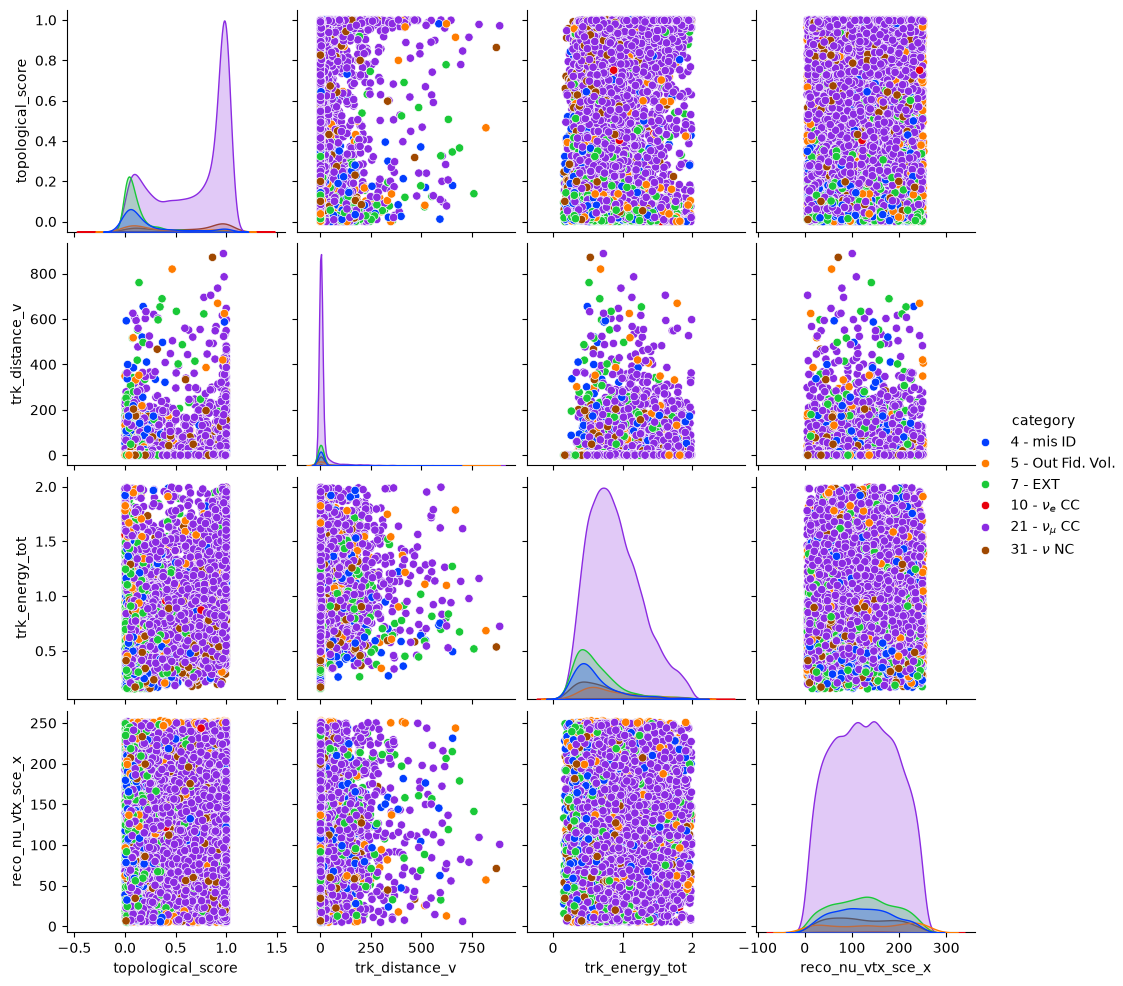

In [5]:
# Visualising a couple of variables.
variable_list = ['category', 'topological_score', 'trk_distance_v', 'trk_energy_tot', 'reco_nu_vtx_sce_x']

# List of categories in text
ptype = [r"mis ID", r"Out Fid. Vol.", r"EXT", r"$\nu_e$ CC", r"$\nu_{\mu}$ CC", r"$\nu$ NC"]

# Plot data
fig = sns.pairplot(MC_EXT_VIS[variable_list], hue = 'category', palette = 'bright')

# Change location of legend
fig._legend.set_bbox_to_anchor((1.05, 0.5))

# Add Category number and type to legend
for t, l in zip(fig._legend.texts, ptype):
   t.set_text(str(t.get_text()) + " - " + str(l))

In [4]:
# Create a deep copy of MC_EXT_VIS without signal events
MC_EXT_BKG = MC_EXT_VIS.copy(deep=True)

MC_EXT_BKG = MC_EXT_BKG.loc[
    MC_EXT_BKG["category"] != 21
].copy()

print("Sample contains signal events: {}".format(len(MC_EXT_VIS)))
print("Background-only sample: {}".format(len(MC_EXT_BKG)))
print(MC_EXT_BKG["category"].value_counts().sort_index())

Sample contains signal events: 14393
Background-only sample: 3945
category
4     1078
5      511
7     1603
10      38
31     715
Name: count, dtype: int64


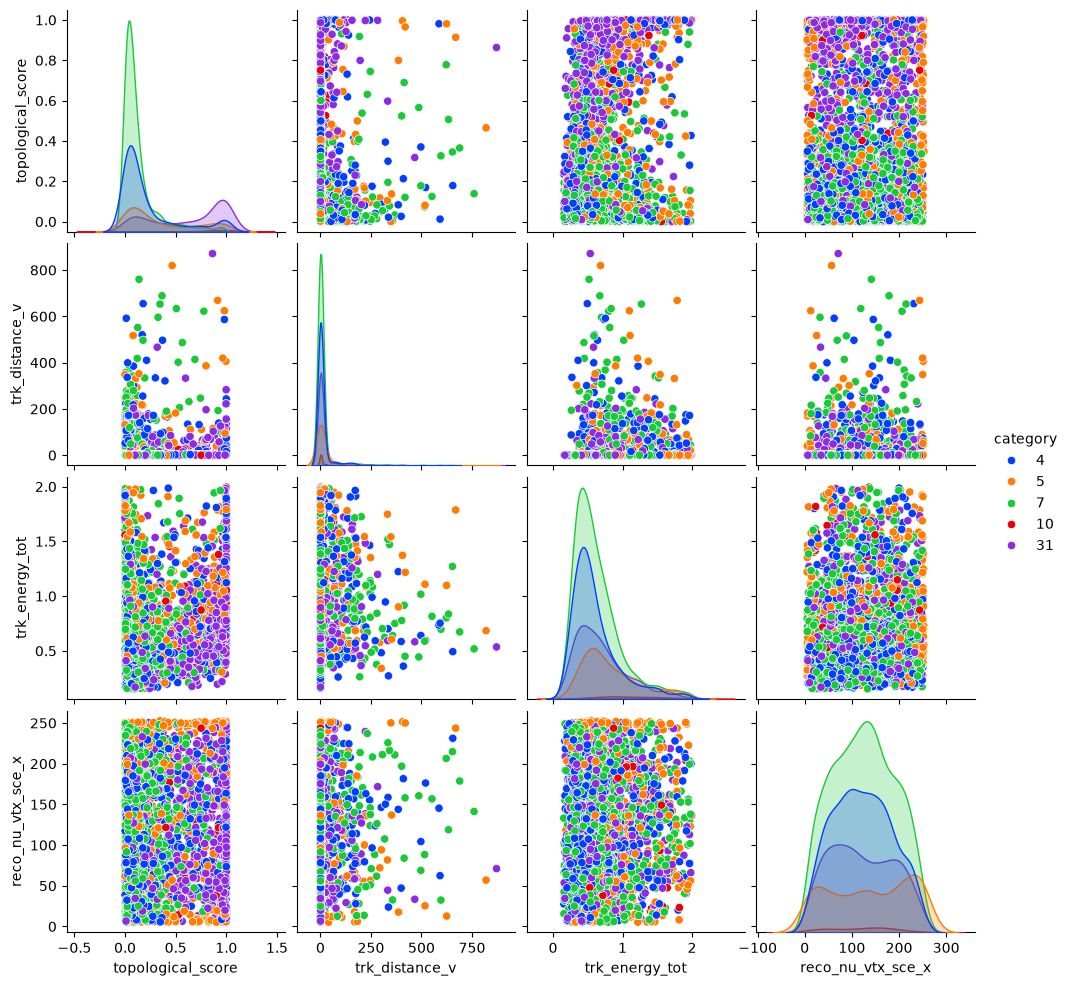

In [7]:
# Plot your background events using sns.pairplot
fig_bkg = sns.pairplot(
    MC_EXT_BKG[variable_list],
    hue="category",
    palette="bright"
)
plt.show()
# List of categories (excluding signal) in text
ptype_no_mu = [r"mid ID", r"Out Fid. Vol.", r"EXT", r"$\nu_e$ CC", r"$\nu$ NC"]


### Bonus 1 Try to apply some of your ideas to make visualising trends more clear

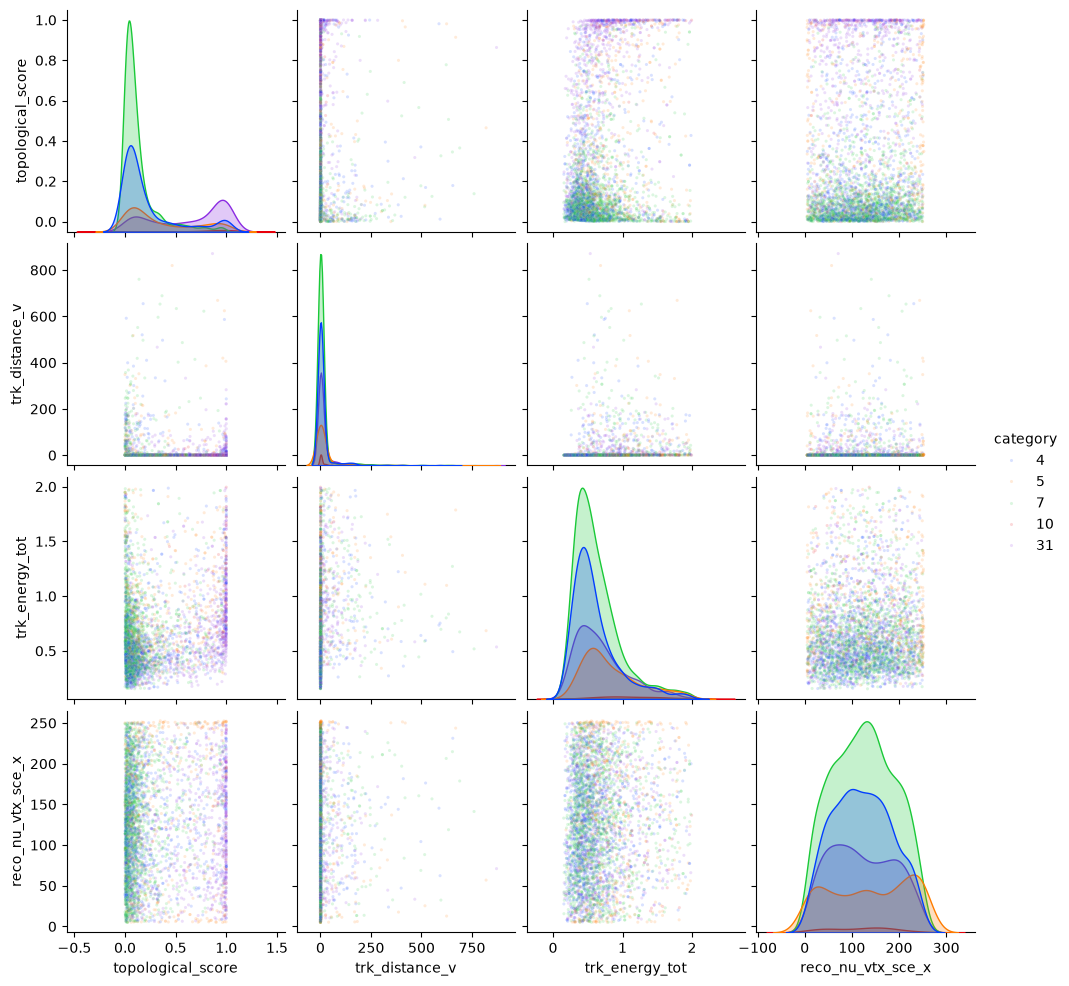

In [8]:
# decrease the size of the points and increase transparency to make trends more clear
fig_bkg = sns.pairplot(
    MC_EXT_BKG[variable_list],
    hue="category",
    palette="bright",
    plot_kws={"s": 5, "alpha": 0.15}
)
plt.show()

### Bonus 2: add other variables to see the trends

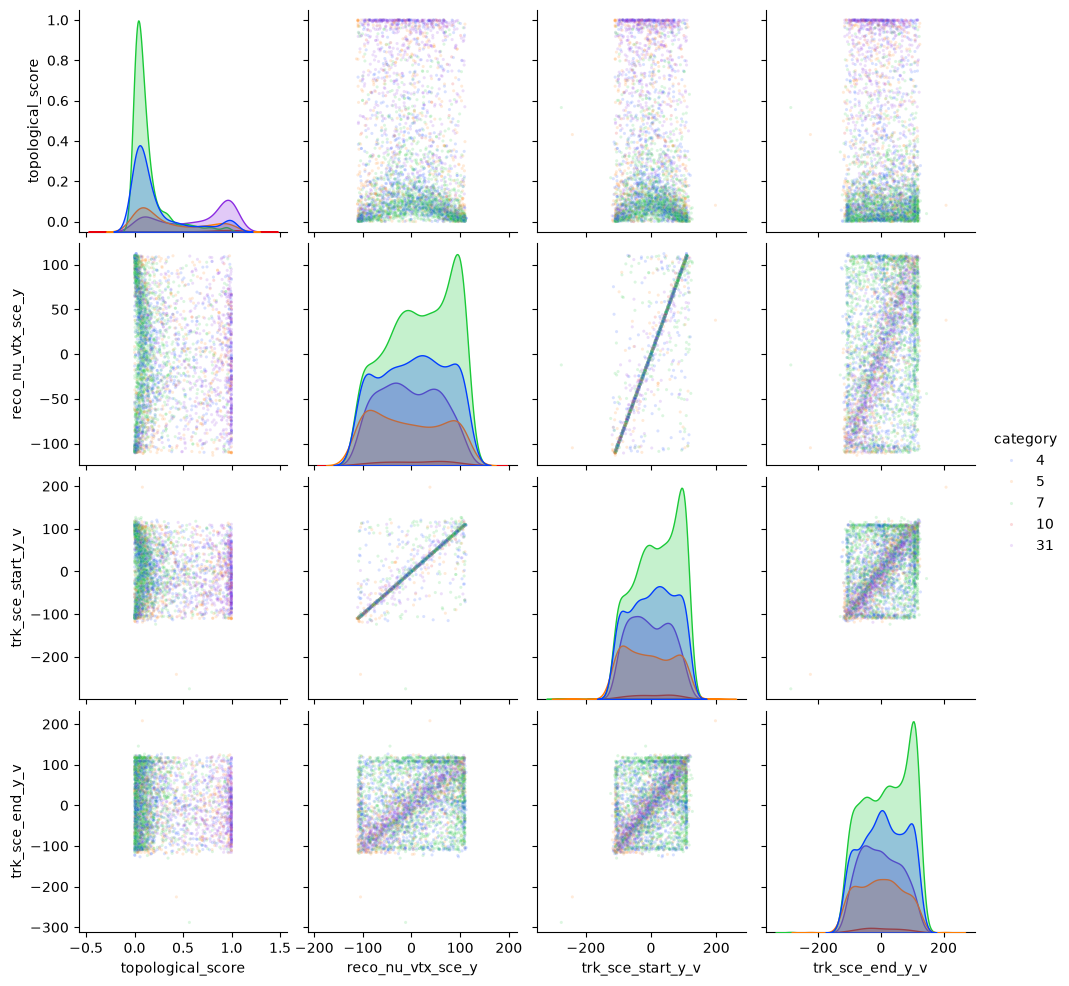

In [9]:
# Add vertical-position variables for Bonus 2
bonus_variables = [
    "topological_score",
    "reco_nu_vtx_sce_y",
    "trk_sce_start_y_v",
    "trk_sce_end_y_v"
]

fig_bonus = sns.pairplot(
    MC_EXT_BKG,
    vars=bonus_variables,
    hue="category",
    palette="bright",
    plot_kws={"s": 5, "alpha": 0.15}
)

plt.show()

In [10]:
# Measure the fraction of reconstructed vertices above y = 0
upper_fraction = (
    MC_EXT_BKG
    .assign(above_midplane=MC_EXT_BKG["reco_nu_vtx_sce_y"] > 0)
    .groupby("category")["above_midplane"]
    .agg(["size", "mean"])
    .rename(columns={
        "size": "Number of events",
        "mean": "Fraction above y = 0"
    })
)

print(upper_fraction.round(3))

          Number of events  Fraction above y = 0
category                                        
4                     1078                 0.527
5                      511                 0.460
7                     1603                 0.590
10                      38                 0.500
31                     715                 0.464


In [5]:
# Make sure to delete dataframe copies if you no longer need them!
del MC_EXT_VIS
del MC_EXT_BKG

# Exercise 6: Random Forest applications

Here we shall modify the shape of our data for its usage in a decision tree, then apply the *RandomForest* method from the skikit-learn package.

In [12]:
# Adjust data shape
features = ['_closestNuCosmicDist', 'trk_len_v', 'trk_distance_v', 'topological_score', 'trk_sce_end_z_v', 'trk_sce_end_y_v', 'trk_sce_end_x_v', 'trk_score_v', 'trk_llr_pid_score_v', 'trk_sce_start_z_v', 'trk_sce_start_y_v', 'trk_sce_start_x_v', 'reco_nu_vtx_sce_x', 'reco_nu_vtx_sce_y', 'reco_nu_vtx_sce_z', 'trk_energy_tot']
output = ['category']

# Setup new database, NEED MORE VALUES
MC_EXT_ML = MC_EXT.copy(deep = True)
MC_EXT_ML = MC_EXT.sample(int(len(MC_EXT)/10), random_state=42)


# Remove muon neutrino and electron neutrino events.

MC_EXT_ML = MC_EXT_ML.loc[
    ~MC_EXT_ML["category"].isin([10, 21])
].copy()

# Print length of dataframe,, with length N
print("Length of MC dataframe: ", len(MC_EXT_ML))

Length of MC dataframe:  31877


In [13]:
# Setting up input parameters for random forest.
X = MC_EXT_ML[features]
y = np.array(MC_EXT_ML['category'])

# Display shape of X and y, should be (N, 16) (N) where is number of samples.

print("X shape:", X.shape)
print("y shape:", y.shape)

# Then split the data up into a "training set" and "test set" using train_test_split.
# Keep the random_state=1 in your arguments
# Split into 80% training data and 20% test data

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

# Print the shape, should now be 
print("Training shapes:", x_train.shape, y_train.shape)
print("Test shapes:", x_test.shape, y_test.shape)


X shape: (31877, 16)
y shape: (31877,)
Training shapes: (25501, 16) (25501,)
Test shapes: (6376, 16) (6376,)


Produce your randomforest model and fit it (dont worry, there is no explicit output, but make sure you haven't made your model too big! It shouldn't take any more than a couple of minutes at most to fit).

In [14]:
# Produce randomforest classifier model and fit to training data
# Keep the random_state=1 in your arguments

rf = RandomForestClassifier(
    n_estimators=1000,
    max_depth=8,
    criterion="gini",
    random_state=1
)

# Fitting takes the input and "truth" data for classification purposes
rf.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",1000
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

Test the accuracies of your results:

In [15]:
# Produce predictions for the classification of your training dataset using your model:
y_pred = rf.predict(x_train)

# plot the accuracies of said predictions
print("Accuracy on training dataset:",metrics.accuracy_score(y_train, y_pred))
rf_acc_train = metrics.accuracy_score(y_train, y_pred)
y_pred = rf.predict(x_test)
print("Accuracy on testing dataset:",metrics.accuracy_score(y_test, y_pred))
rf_acc_test = metrics.accuracy_score(y_test, y_pred)

Accuracy on training dataset: 0.6608368299282381
Accuracy on testing dataset: 0.6535445420326224


If your training accuracy is similar to your testing accuracy, this demonstrates that you haven't overfit your data!

#### Confusion matrix and variable importance

Produce a confusion matrix for your model to quantify its ability to predict your different interaction types.

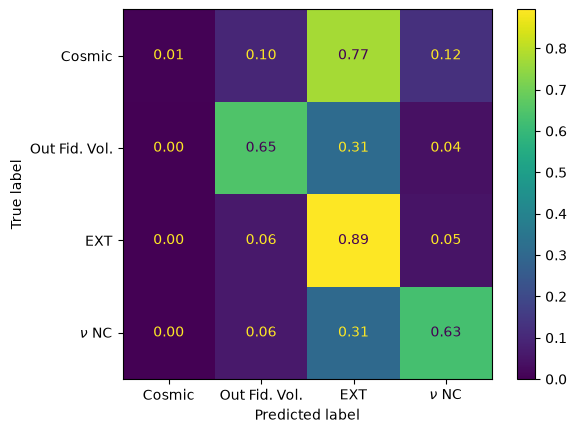

In [16]:
# For labelling your confusion matrix
ptype_no_mu_e = [r"Cosmic", r"Out Fid. Vol.", r"EXT", r"$\nu$ NC"]

# plot your confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[4, 5, 7, 31],
    normalize="true"
)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=ptype_no_mu_e)
disp.plot(values_format=".2f")
plt.show()


Print the number of event on each category

In [19]:
# Print the number of events in each category used for the model
print(MC_EXT_ML["category"].value_counts().sort_index())

category
4      5061
5      9579
7     13491
31     3746
Name: count, dtype: int64


Plot the importance of your different parameters.

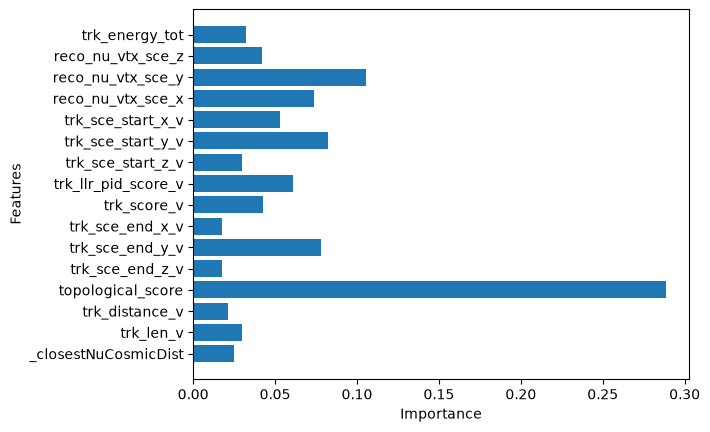

In [17]:
# Plot importance
importance = rf.feature_importances_
ytix = features

plt.barh(range(16), importance)
plt.yticks(range(16), features)
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()


# Neutrino_functions.py

You are given access to a couple of template functions provided within Neutrino_functions.py, which may be helpful in completing this lab. One such function is 'Neutrino_functions.histogram_plot', which can be seen below, but you can create your own functions if you wish.

In [18]:
#This command shows what input you should give the plotting function. The inputs with =None can be left out when calling the function
help(Neutrino_functions.histogram_plot)

Help on function histogram_plot in module Neutrino_functions:

histogram_plot(MC_frame, variable, bins, name, scaling, xlims=[], plot_fig=True, plot_data=False, logscale=None, dataFrame=None, Stat_func=None)
    MC_frame: pandas dataframe - MC dataframe
    variable: string - name of the variable
    bins: int - number of bins
    name: string - name of the plot. The plot is saved
    scaling: array/list - weights you want to apply on MC data
    plot_data: boolean - if True then plots data as well
    logscale: boolean - if True then y axis is log scale
    dataFrame: pandas dataframe - data dataframe



# Exercise 7: Selection Cuts and Histogram plotting

Modify selection cuts. Remember to cut the same variables in both data sets.

In [ ]:
# Load an unselected baseline for comparing selection cuts (Template Example)
# MC_EXT_uncut = pd.read_pickle(MC_file).drop("Subevent", axis=1)
# data_uncut = pd.read_pickle(data_file).drop("Subevent", axis=1)

In [6]:
#Remove the exterme trk_energy_tot events that come from the mis-reconstructed / non-physical events to recover the correct eff and purity.
# Load the original samples
MC_EXT_uncut = pd.read_pickle(MC_file).drop("Subevent", axis=1)
data_uncut = pd.read_pickle(data_file).drop("Subevent", axis=1)

# Remove failed-reconstruction entries with placeholder energies around 10000 GeV
MC_EXT_uncut = MC_EXT_uncut.loc[
    MC_EXT_uncut["trk_energy_tot"] < 1000
].copy()

data_uncut = data_uncut.loc[
    data_uncut["trk_energy_tot"] < 1000
].copy()

In [7]:
def Selections(frame):
    
    # Basic variables present in dataframe 
    trk_start_x_v = frame['trk_sce_start_x_v']        # cm
    trk_start_y_v = frame['trk_sce_start_y_v']        # cm
    trk_start_z_v = frame['trk_sce_start_z_v']        # cm
    trk_end_x_v = frame['trk_sce_end_x_v']            # cm
    trk_end_y_v = frame['trk_sce_end_y_v']            # cm
    trk_end_z_v = frame['trk_sce_end_z_v']            # cm
    reco_x = frame['reco_nu_vtx_sce_x']               # cm
    reco_y = frame['reco_nu_vtx_sce_y']               # cm
    reco_z = frame['reco_nu_vtx_sce_z']               # cm
    topological = frame['topological_score']          # N/A
    trk_score_v = frame['trk_score_v']                # N/A
    trk_dis_v = frame['trk_distance_v']               # cm
    trk_len_v = frame['trk_len_v']                    # cm
    trk_energy_tot = frame['trk_energy_tot']          # GeV 
    
    
    
    # select the conditions you want to apply, here is an initial condition to get you started.
    selection = (
    (trk_energy_tot > 0) &
    (trk_energy_tot < 2) &
    (reco_x > 10) &
    (reco_x < 245) &
    (reco_y > -100) &
    (reco_y < 100) &
    (reco_z > 20) &
    (reco_z < 1000) &
    (topological > 0.2)
)
    
    # Apply selection on dataframe
    frame = frame[selection]
    
    return frame

## Calls the selection function on the dataframes

In [8]:

MC_EXT = Selections(MC_EXT_uncut)
data_frame = Selections(data_uncut)

# Plot all variables and decide on selection cuts
Here is the section with the example histogram plots for each variable. Create a new cell and implement your own function to plot all the histograms.

In [9]:
# Common variables in both dataframes
all_variables_to_plot = list(set(list(MC_EXT)).intersection(list(data_frame)))
print(all_variables_to_plot)


['trk_sce_end_y_v', 'trk_llr_pid_score_v', 'trk_sce_end_z_v', 'trk_range_muon_mom_v', 'trk_distance_v', 'reco_nu_vtx_sce_x', 'trk_mcs_muon_mom_v', 'trk_sce_start_y_v', 'reco_nu_vtx_sce_z', 'trk_score_v', 'trk_sce_end_x_v', 'category', 'trk_sce_start_x_v', 'trk_energy_tot', 'reco_nu_vtx_sce_y', 'trk_len_v', 'topological_score', 'trk_sce_start_z_v', '_closestNuCosmicDist']


### Plot functions

In [10]:
def plot_variable(frame, variable, binrange=None):
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=frame,
        x=variable,
        hue="category",
        hue_order=[4, 5, 7, 10, 21, 31],
        multiple="stack",
        weights="weight",
        palette="deep",
        bins=40,
        binrange=binrange
    )

    plt.xlabel(variable)
    plt.ylabel("Weighted events")
    plt.tight_layout()
    plt.show()

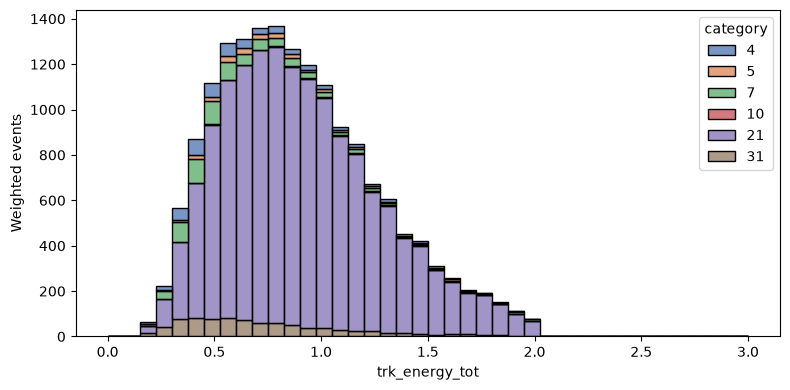

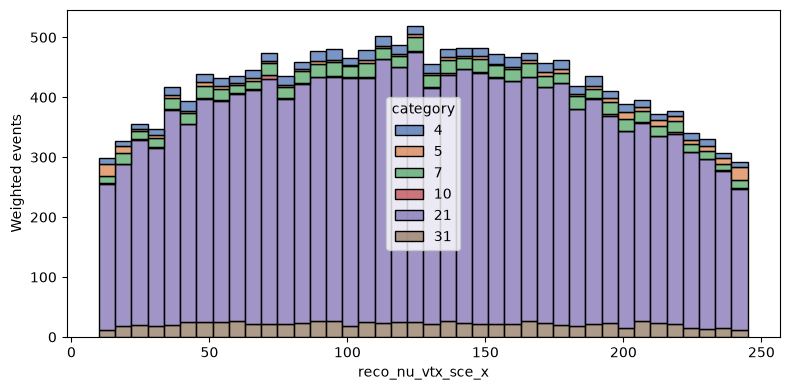

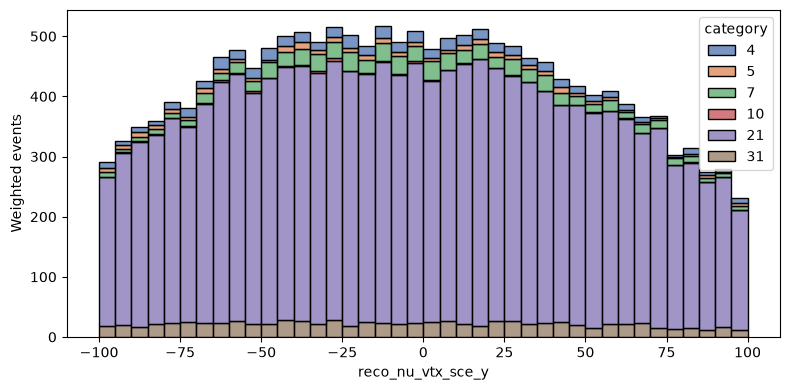

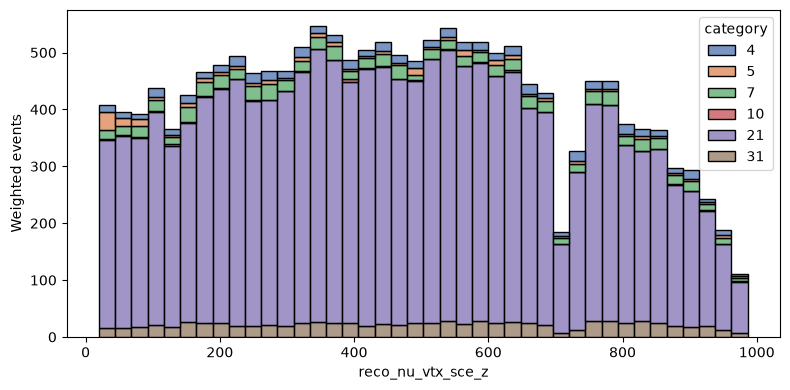

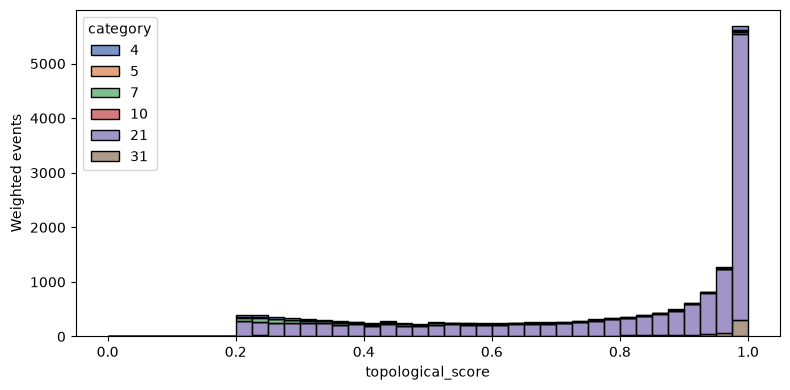

In [11]:
#Before applying any cuts
#plot_variable(MC_EXT, "trk_energy_tot", binrange=(0, 3))
#plot_variable(MC_EXT, "reco_nu_vtx_sce_x")
#plot_variable(MC_EXT, "reco_nu_vtx_sce_y")
#plot_variable(MC_EXT, "reco_nu_vtx_sce_z")
#plot_variable(MC_EXT, "topological_score", binrange=(0, 1))

#After applying cuts
plot_variable(MC_EXT, "trk_energy_tot", binrange=(0, 3))
plot_variable(MC_EXT, "reco_nu_vtx_sce_x")
plot_variable(MC_EXT, "reco_nu_vtx_sce_y")
plot_variable(MC_EXT, "reco_nu_vtx_sce_z")
plot_variable(MC_EXT, "topological_score", binrange=(0, 1))

# Exercise 8: Check the purity and efficiency of the sample
It is recommended to plot purity and efficiency after each variable cut.

**HINT:** Function Selection() has commented lines of code that you may find useful for purpose of plotting changes in purity/efficiency after every cut.

In [12]:
# Weighted signal yields before and after selection
signal_before = MC_EXT_uncut.loc[
    MC_EXT_uncut["category"] == 21, "weight"
].sum()

signal_after = MC_EXT.loc[
    MC_EXT["category"] == 21, "weight"
].sum()

# Total weighted yields
total_before = MC_EXT_uncut["weight"].sum()
total_after = MC_EXT["weight"].sum()

# Calculate purity and efficiency
purity_before = signal_before / total_before
purity_after = signal_after / total_after
efficiency = signal_after / signal_before

print(f"MC events before: {len(MC_EXT_uncut)}")
print(f"MC events after: {len(MC_EXT)}")
print(f"Purity before: {purity_before:.2%}")
print(f"Purity after: {purity_after:.2%}")
print(f"Signal efficiency: {efficiency:.2%}")

MC events before: 150365
MC events after: 94296
Purity before: 70.36%
Purity after: 85.85%
Signal efficiency: 73.56%


In [13]:
# Inspect the signal energy distribution before selection
signal = MC_EXT_uncut.loc[
    MC_EXT_uncut["category"] == 21
]

print(signal["trk_energy_tot"].describe(
    percentiles=[0.1, 0.5, 0.9, 0.99]
))

print("Missing energy values:",
      signal["trk_energy_tot"].isna().sum())

count    110114.000000
mean          0.979955
std           0.520616
min           0.159077
10%           0.458524
50%           0.874962
90%           1.607352
99%           2.810248
max          16.799489
Name: trk_energy_tot, dtype: float64
Missing energy values: 0


# Exercise 9: Plot the energy spectrums here and normalise

Final representation of MC and data after applying the cuts.

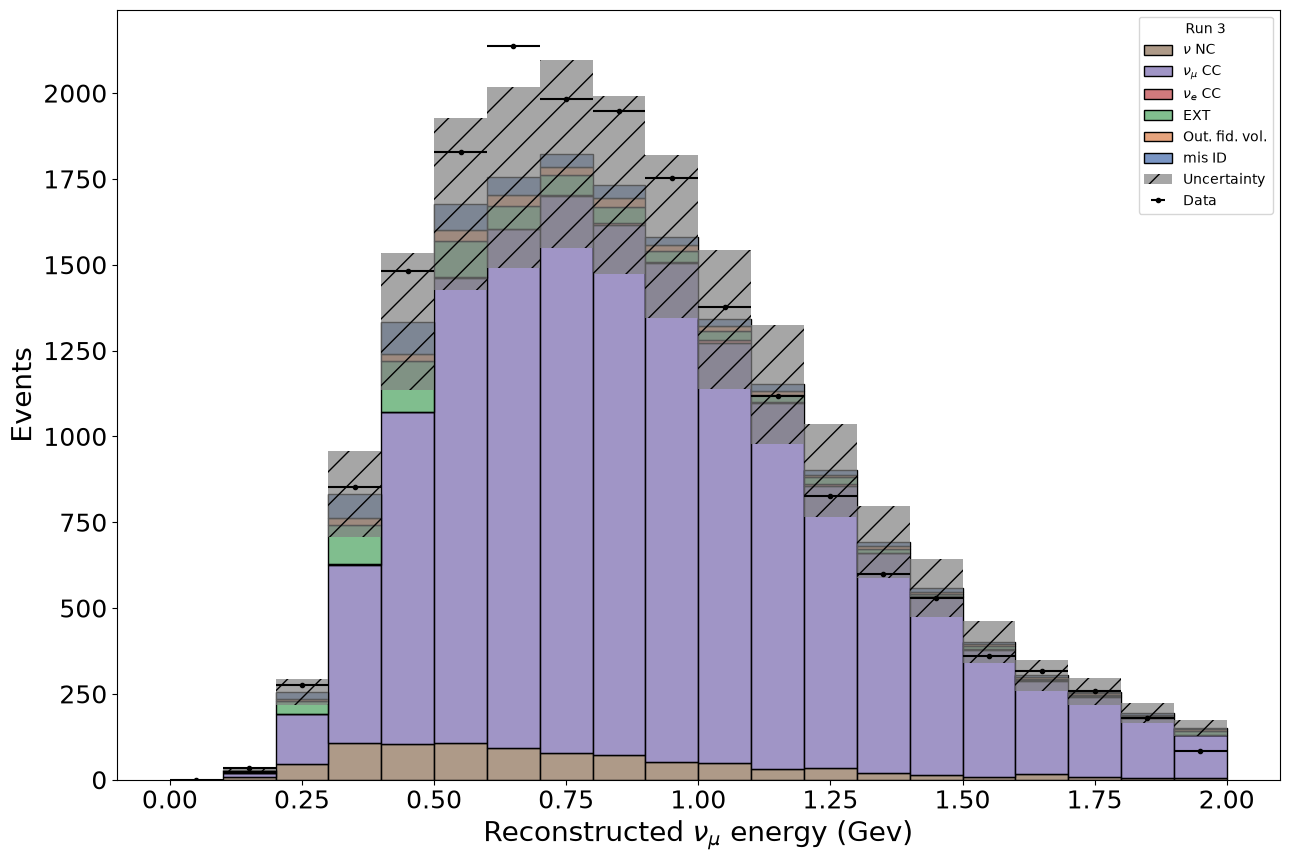

In [28]:
MC_heights, data_heights = Neutrino_functions.histogram_plot(
    MC_frame=MC_EXT,
    variable="trk_energy_tot",
    bins=20,
    name="Ex9_energy_spectrum",
    scaling=MC_EXT["weight"],
    xlims=[0, 2],
    plot_data=True,
    dataFrame=data_frame,
    logscale=False
)

### Bonus: total unc.:

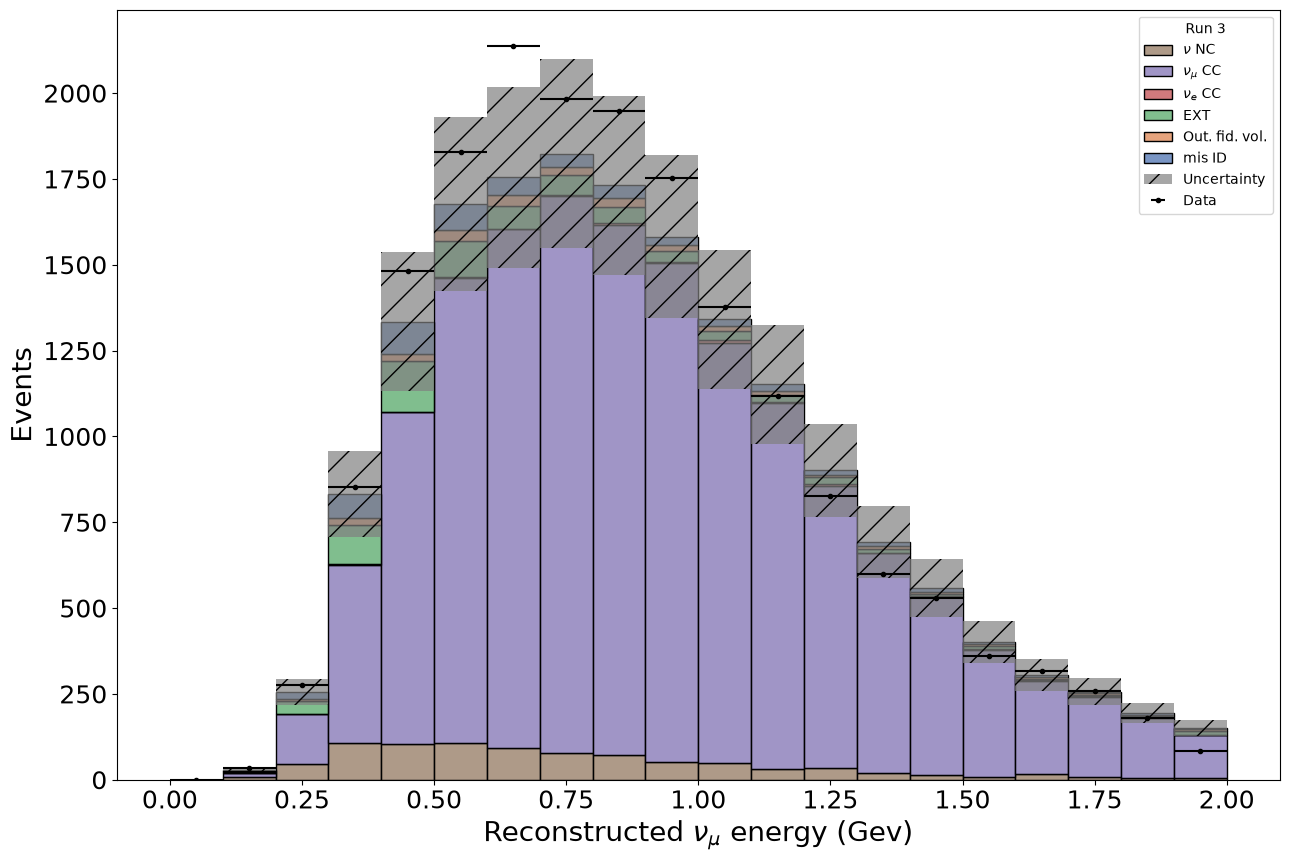

In [14]:
# Use the same 20 bins over 0-2 GeV as the original plot
bin_edges = np.linspace(0, 2, 21)

# Sum the squared event weights in each bin
mc_sumw2, _ = np.histogram(
    MC_EXT["trk_energy_tot"],
    bins=bin_edges,
    weights=MC_EXT["weight"] ** 2
)

# The template expects a fractional statistical uncertainty
def mc_relative_stat(mc_heights):
    mc_heights = np.asarray(mc_heights, dtype=float)

    return np.divide(
        np.sqrt(mc_sumw2),
        mc_heights,
        out=np.zeros_like(mc_heights),
        where=mc_heights != 0
    )

# Combine statistical and systematic uncertainties in the template
MC_heights, data_heights = Neutrino_functions.histogram_plot(
    MC_frame=MC_EXT,
    variable="trk_energy_tot",
    bins=20,
    name="Ex9_bonus_energy_spectrum",
    scaling=MC_EXT["weight"],
    xlims=[0, 2],
    plot_data=True,
    dataFrame=data_frame,
    logscale=False,
    Stat_func=mc_relative_stat
)

# Exercise 10: Oscillation and fitting

### a) Define functions requires for Oscillation analysis, test that they work!


In [15]:
def survival_probability(E, delta_m2, sin2_2theta, L=0.47):
    E = np.asarray(E)

    return 1 - sin2_2theta * np.sin(
        1.27 * delta_m2 * L / E
    ) ** 2

In [ ]:
# Test
print("No oscillation:", survival_probability(1.0, 1.0, 0.0))
print("Example probability:", survival_probability(1.0, 1.0, 0.5))

No oscillation: 1.0
Example probability: 0.8420323488235437


In [16]:
# muon disappearance application to reconstructed neutrino energy
def apply_oscillation(frame, delta_m2, sin2_2theta):
    result = frame.copy(deep=True)

    # Apply disappearance to the muon-neutrino CC signal
    signal = result["category"] == 21

    probability = survival_probability(
        result.loc[signal, "true_E"],
        delta_m2,
        sin2_2theta
    )

    result.loc[signal, "weight"] = (
        result.loc[signal, "weight"] * probability
    )

    return result

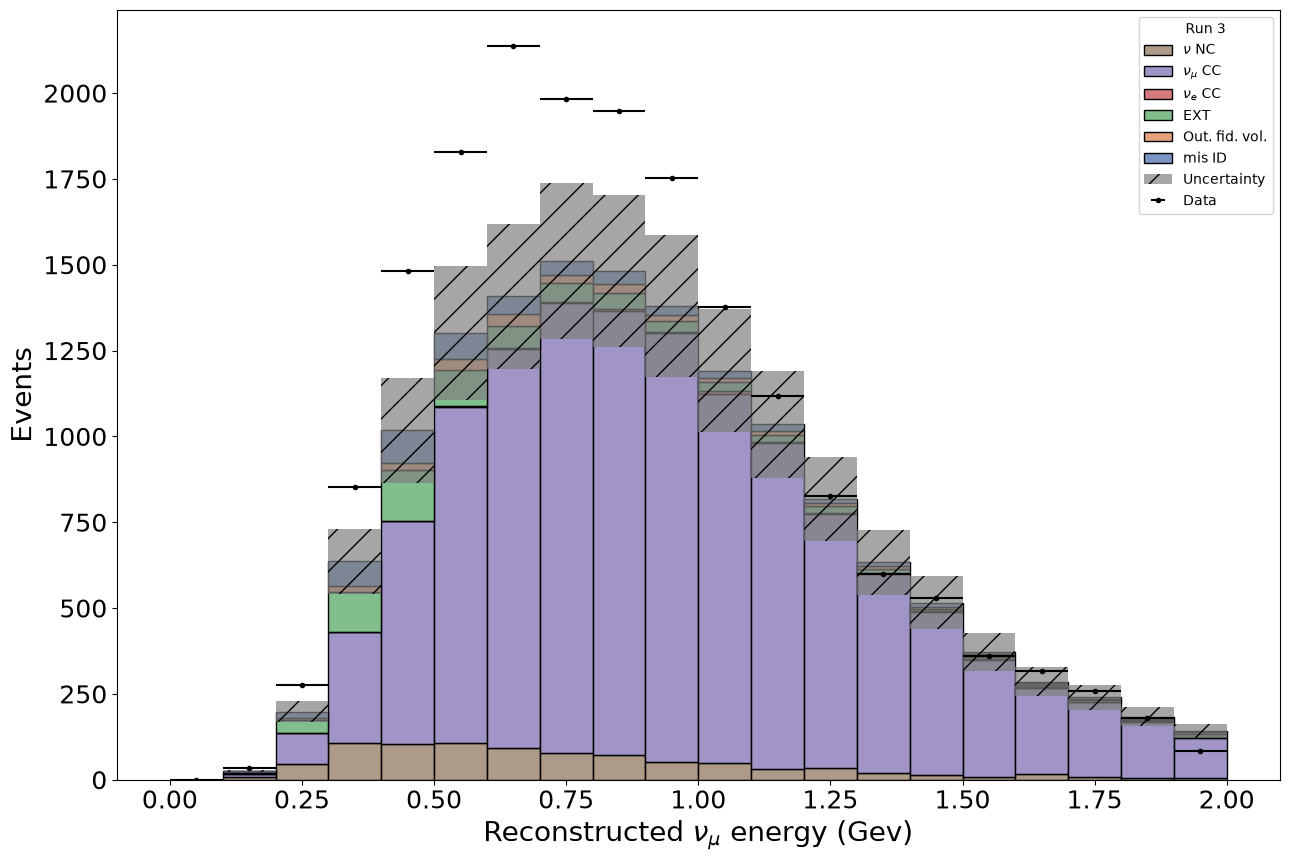

In [17]:
MC_osc = apply_oscillation(
    MC_EXT,
    delta_m2=1,
    sin2_2theta=0.5
)

MC_osc_heights, data_heights = Neutrino_functions.histogram_plot(
    MC_frame=MC_osc,
    variable="trk_energy_tot",
    bins=20,
    name="Ex10_oscillated_spectrum",
    scaling=MC_osc["weight"],
    xlims=[0, 2],
    plot_data=True,
    dataFrame=data_frame,
    logscale=False
)

In [18]:
# chi squared function
def chi_squared(prediction, observed, uncertainty):
    prediction = np.asarray(prediction)
    observed = np.asarray(observed)
    uncertainty = np.asarray(uncertainty)

    # A nonzero discrepancy with zero uncertainty is undefined
    if np.any(
        (uncertainty == 0) & (prediction != observed)
    ):
        return np.inf

    # Empty bins with zero prediction and data contribute nothing
    valid = uncertainty > 0

    return np.sum(
        ((prediction[valid] - observed[valid])
         / uncertainty[valid]) ** 2
    )

In [19]:
# Use identical bins for predictions and real data
bin_edges = np.linspace(0, 2, 21)

observed, _ = np.histogram(
    data_frame["trk_energy_tot"],
    bins=bin_edges
)

prediction_no_osc, _ = np.histogram(
    MC_EXT["trk_energy_tot"],
    bins=bin_edges,
    weights=MC_EXT["weight"]
)

prediction_osc, _ = np.histogram(
    MC_osc["trk_energy_tot"],
    bins=bin_edges,
    weights=MC_osc["weight"]
)

# Use 15% of each model's predicted yield as its uncertainty
chi2_no_osc = chi_squared(
    prediction_no_osc, observed, 0.15 * prediction_no_osc
)

chi2_osc = chi_squared(
    prediction_osc, observed, 0.15 * prediction_osc
)

print(f"Chi-squared without oscillation: {chi2_no_osc:.2f}")
print(f"Chi-squared with oscillation: {chi2_osc:.2f}")

Chi-squared without oscillation: 16.44
Chi-squared with oscillation: 66.43


# Exercise 11/12: Oscillation parameter scan, contour plotting, closure test.

### Closure test, create your oscillation parameter scanning code, and find minimum values for chi squared!

In [20]:
# Selection cuts on oscillated data
# Load the reference sample and apply the same selection
closure_data = pd.read_pickle("./data/oscillated_data.pkl")
closure_data = Selections(closure_data)

# Use the same reconstructed-energy bins as before
bin_edges = np.linspace(0, 2, 21)

closure_target, _ = np.histogram(
    closure_data["trk_energy_tot"],
    bins=bin_edges,
    weights=closure_data["weight"]
)

In [21]:
MC_EXT = Selections(MC_EXT_uncut)

In [22]:
# Function that oscillates and calculates chi squared for set delM21 and sin^2(2theta)
def closure_chi2(delta_m2, sin2_2theta):
    # Reproduce the all-category reweighting of the reference file
    probability = survival_probability(
        MC_EXT["true_E"],
        delta_m2,
        sin2_2theta
    )

    oscillated_weights = MC_EXT["weight"] * probability

    prediction, _ = np.histogram(
        MC_EXT["trk_energy_tot"],
        bins=bin_edges,
        weights=oscillated_weights
    )

# Use syst., 15% of the prediction as the uncertainty for chi-squared calculation

    uncertainty = 0.15 * prediction

    return chi_squared(
        prediction,
        closure_target,
        uncertainty
    )

In [23]:
# Function that loops the above function across range of values of delM21 and sin^2(2theta)
def scan_closure(dm_values, amplitude_values):
    grid = np.zeros((len(dm_values), len(amplitude_values)))

    for i, delta_m2 in enumerate(dm_values):
        for j, amplitude in enumerate(amplitude_values):
            grid[i, j] = closure_chi2(delta_m2, amplitude)

    return grid

In [24]:
# Rough scan of the parameter space to find the best-fit values
dm_values = np.linspace(0.0001, 50, 101)
amplitude_values = np.linspace(0.1, 1.0, 46)

chi2_grid = scan_closure(dm_values, amplitude_values)

# Find the grid point with the smallest chi-squared
i_best, j_best = np.unravel_index(
    np.argmin(chi2_grid),
    chi2_grid.shape
)

best_dm = dm_values[i_best]
best_amplitude = amplitude_values[j_best]

print(f"Best delta_m2: {best_dm:.4f} eV^2")
print(f"Best sin2_2theta: {best_amplitude:.4f}")
print(f"Minimum chi-squared: {chi2_grid[i_best, j_best]:.6f}")

Best delta_m2: 11.0001 eV^2
Best sin2_2theta: 0.5600
Minimum chi-squared: 0.038331


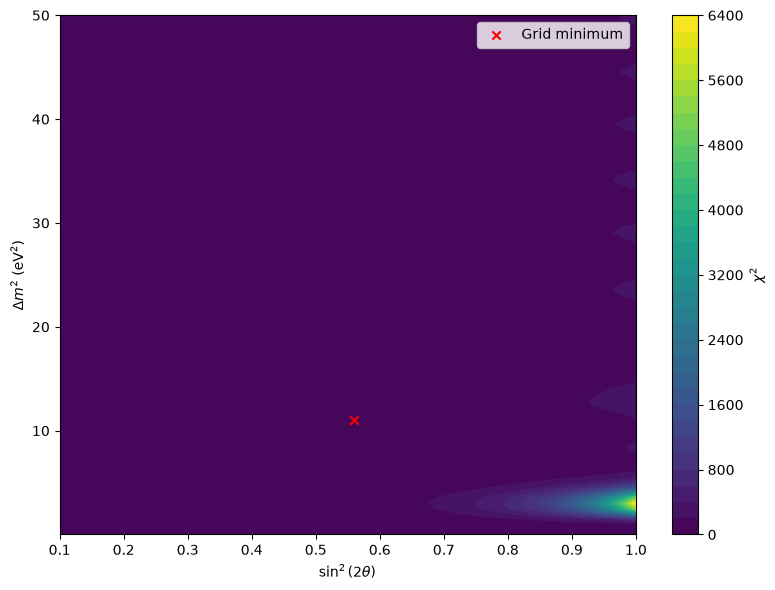

In [25]:
# plot contourf function and find minimum!
plt.figure(figsize=(8, 6))

filled = plt.contourf(
    amplitude_values,
    dm_values,
    chi2_grid,
    levels=40,
    cmap="viridis"
)

plt.colorbar(filled, label=r"$\chi^2$")
plt.scatter(
    best_amplitude,
    best_dm,
    color="red",
    marker="x",
    label="Grid minimum"
)

plt.xlabel(r"$\sin^2(2\theta)$")
plt.ylabel(r"$\Delta m^2$ (eV$^2$)")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Scan a finer grid around the minimum found in the coarse scan
dm_fine = np.linspace(8, 15, 141)
amplitude_fine = np.linspace(0.38, 0.75, 101)

chi2_fine = scan_closure(dm_fine, amplitude_fine)

i_fine, j_fine = np.unravel_index(
    np.argmin(chi2_fine), chi2_fine.shape
)
best_dm_fine = dm_fine[i_fine]
best_amplitude_fine = amplitude_fine[j_fine]
chi2_min = chi2_fine[i_fine, j_fine]
delta_chi2_fine = chi2_fine - chi2_min

print(f"Best delta_m2: {best_dm_fine:.2f} eV^2")
print(f"Best sin2_2theta: {best_amplitude_fine:.4f}")
print(f"Minimum chi-squared: {chi2_min:.6f}")
print(f"Grid spacing in delta_m2: {dm_fine[1] - dm_fine[0]:.2f} eV^2")
print(f"Grid spacing in amplitude: {amplitude_fine[1] - amplitude_fine[0]:.4f}")


Best delta_m2: 11.10 eV^2
Best sin2_2theta: 0.5576
Minimum chi-squared: 0.001334
Grid spacing in delta_m2: 0.05 eV^2
Grid spacing in amplitude: 0.0037


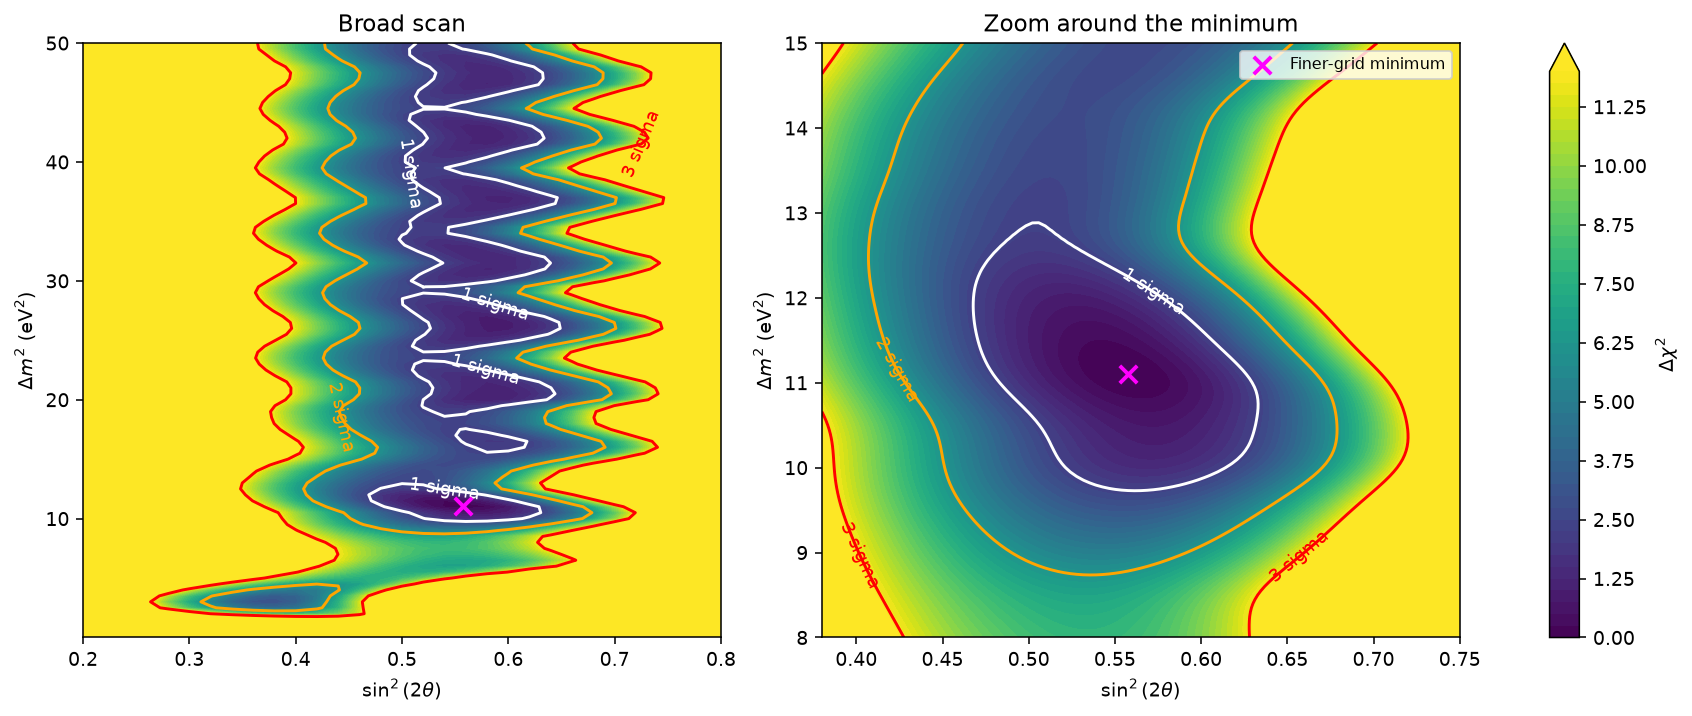

In [ ]:
# Reuse the existing coarse and finer scans for a side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

plots = [
    (amplitude_values, dm_values, chi2_grid - chi2_min, "Broad scan"),
    (amplitude_fine, dm_fine, delta_chi2_fine, "Zoom around the minimum")
]

for ax, (amplitudes, masses, delta_chi2, title) in zip(axes, plots):
    filled = ax.contourf(
        amplitudes, masses, delta_chi2,
        levels=np.linspace(0, 12, 49), cmap="viridis", extend="max"
    )
    contours = ax.contour(
        amplitudes, masses, delta_chi2,
        levels=[2.30, 6.18, 11.83],
        colors=["white", "orange", "red"], linewidths=1.5
    )
    ax.clabel(
        contours,
        fmt={2.30: "1 sigma", 6.18: "2 sigma", 11.83: "3 sigma"},
        inline=False, fontsize=9
    )
    ax.scatter(
        best_amplitude_fine, best_dm_fine,
        color="magenta", marker="x", s=80, linewidths=2,
        label="Finer-grid minimum", zorder=5
    )
    ax.set(
        xlabel=r"$\sin^2(2\theta)$",
        ylabel=r"$\Delta m^2$ (eV$^2$)",
        title=title
    )

axes[0].set_xlim(0.2, 0.8)
axes[1].set_xlim(amplitude_fine[0], amplitude_fine[-1])
axes[1].set_ylim(dm_fine[0], dm_fine[-1])
axes[1].legend(loc="upper right", fontsize=8)
fig.colorbar(filled, ax=axes, label=r"$\Delta\chi^2$")
fig.savefig("output/day4/ex11a_closure_zoom.png", dpi=180)
plt.show()


### Confidence levels and parameter minima. 
Determine confidence levels, and find the parameter values that correspond to the lowest chi squared value within your range.with

In [ ]:
# Estimate local parameter intervals from the joint 1-sigma region
one_sigma = delta_chi2_fine <= 2.30

# A region cut off by the scan boundary cannot give a complete interval
if (one_sigma[0].any() or one_sigma[-1].any()
        or one_sigma[:, 0].any() or one_sigma[:, -1].any()):
    print("The 1-sigma region reaches a scan boundary; expand the range first.")
else:
    dm_allowed = dm_fine[np.any(one_sigma, axis=1)]
    amplitude_allowed = amplitude_fine[np.any(one_sigma, axis=0)]
    dm_low, dm_high = dm_allowed.min(), dm_allowed.max()
    amplitude_low, amplitude_high = amplitude_allowed.min(), amplitude_allowed.max()

    print("Local joint 1-sigma projections: Delta chi2 <= 2.30")
    print(f"sin2_2theta = {best_amplitude_fine:.3f} "
          f"+{amplitude_high - best_amplitude_fine:.3f} "
          f"-{best_amplitude_fine - amplitude_low:.3f}")
    print(f"Amplitude interval: [{amplitude_low:.3f}, {amplitude_high:.3f}]")
    print(f"delta_m2 = {best_dm_fine:.2f} "
          f"+{dm_high - best_dm_fine:.2f} "
          f"-{best_dm_fine - dm_low:.2f} eV^2")
    print(f"Mass-squared interval: [{dm_low:.2f}, {dm_high:.2f}] eV^2")
    print("Intervals are estimated from the grid; grid spacing is not a statistical error.")


Local joint 1-sigma projections: Delta chi2 <= 2.30
sin2_2theta = 0.558 +0.074 -0.089
Amplitude interval: [0.469, 0.632]
delta_m2 = 11.10 +1.75 -1.35 eV^2
Mass-squared interval: [9.75, 12.85] eV^2
Intervals are estimated from the grid; grid spacing is not a statistical error.


**Interpretation of the closure test**

- The reference file applies the oscillation factor to all categories, including backgrounds. The closure calculation follows the same teaching simplification, with a 15% systematic uncertainty in each bin.
- Two oscillation parameters are fitted, so the joint 1, 2 and 3 sigma contours use Delta chi-squared thresholds of 2.30, 6.18 and 11.83. These differ from one-parameter thresholds.
- The printed intervals are projections of the closed local joint 1-sigma region around the recovered minimum. They do not include any separate allowed regions outside this zoom. The chosen zoom should contain only the local region being reported.
- The 2- and 3-sigma contours extend beyond the finer plot. Their endpoints at the plot boundary are not confidence limits. The coarse scan provides wider context; this local plot alone cannot establish an upper limit on the mass-squared difference.
- Different oscillation parameters can produce similar binned spectra. Applying oscillations to backgrounds also changes the contour structure, but the simplification alone does not prove why a contour is open.


# Exercise 13/14: 3+1 Framework Neutrino disappearance.

In [27]:
# Produce your new oscillation parameter, which should be sin^2(2*theta_ue)

# Compare your result with MiniBooNE

Results are extracted from MiniBooNE (orange) and LSND (blue)

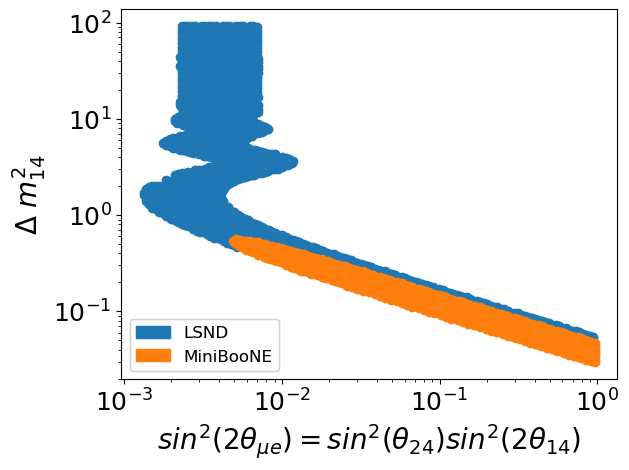

In [2]:
# Load data
LSND_data = pd.read_csv('./data/DataSet_LSND.csv').to_numpy()
MiniBooNE_data = pd.read_csv('./data/DataSet_MiniBooNE.csv').to_numpy()

# Plot data
plt.plot(LSND_data[:,0],LSND_data[:,1],'o')
plt.plot(MiniBooNE_data[:,0],MiniBooNE_data[:,1],'o')

# Producing MiniBooNE/LSND legend
LSND_path = mpatches.Patch(color='tab:blue', label = 'LSND')
MINI_path = mpatches.Patch(color='tab:orange', label = 'MiniBooNE')
first_legend = plt.legend(handles=[LSND_path, MINI_path], loc = 'lower left', fontsize = 12)
plt.gca().add_artist(first_legend)


plt.xlabel(r'$sin^2(2\theta_{\mu e})=sin^2(\theta_{24})sin^2(2\theta_{14})$',fontsize=20)
plt.ylabel(r'$\Delta$ $m_{14}^2$',fontsize=20)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.yscale('log')
plt.xscale('log')
plt.show()